# 16 — Week 4: freeze the benchmark and evaluate ONCE on the test split

Protocol (provisional decisions, Week 4):
1. Model set frozen: the 18 validation-benchmark models plus the zero-shot foundation models (Chronos-Bolt small,
   context 512; TimesFM 2.5 if notebook 15 has run, with its validation-chosen context).
2. Training data: train only, no refit on train + validation. Networks: the saved checkpoints. LightGBM: tuned
   parameters and rounds refit on train, seeds 0-2. ARIMA/ETS: fixed parameters as filters. Ridge AR: train refit with
   the validation alpha.
3. Same metrics as validation, plus weekly skill, Diebold-Mariano with Holm correction and the ramp breakdown.
4. One run. **Cells 2 and 3 do not touch the test split.** Cell 2 re-creates every validation forecast from the frozen
   settings and must match the stored forecasts (max difference < 0.001 kW); cell 3 writes the freeze record.
   Only then cell 4 opens the test split. Results are reported whatever they are; a later bug fix is reported as such.

Runtime: cell 2 about 15-25 min (LightGBM refits), cell 4 about 20-30 min. Run `caffeinate -dis` in a Terminal.

In [1]:
# Cell 1: setup
import os
os.environ["HF_HUB_OFFLINE"] = "1"
import sys, json, time, hashlib, subprocess, warnings, logging
from pathlib import Path
import numpy as np
import polars as pl

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
for nm in ("pytorch_lightning", "lightning", "lightning.pytorch", "lightning_fabric"):
    logging.getLogger(nm).setLevel(logging.ERROR)
from evaluation import frozen as F
from evaluation import metrics as M
from evaluation import compare as C

REP = ROOT / "reports" / "week4"
FIG = ROOT / "reports" / "figures" / "week4"
REP.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
HORIZONS = F.HORIZONS
pl.Config.set_tbl_rows(80); pl.Config.set_tbl_cols(20); pl.Config.set_tbl_width_chars(240)
ctx = F.Ctx(ROOT)
print("usable origins:", {h: {s: len(ctx.IDX[h][s]) for s in ("train", "val", "test")} for h in HORIZONS})
FREEZE_F = REP / "test_freeze.json"
print("freeze record exists:", FREEZE_F.exists(), "(if True, the test split was already opened once)")


def collect(split, log=print):
    """All trained-model forecasts for a split: {h: {model: {seed: yhat}}}."""
    t0 = time.time()
    out = {h: {} for h in HORIZONS}
    b = F.predict_baselines(ctx, split)
    s_, info = F.predict_statespace(ctx, split)
    log(f"baselines + state space: {time.time() - t0:.0f} s")
    g = F.predict_lightgbm(ctx, split, log=log)
    log(f"LightGBM: {time.time() - t0:.0f} s")
    nn = F.predict_networks(ctx, split, log=log)
    log(f"networks: {time.time() - t0:.0f} s")
    for h in HORIZONS:
        for d in (b[h], s_[h]):
            for m, v in d.items():
                out[h][m] = {0: v}
        out[h].update(g[h]); out[h].update(nn[h])
    return out, info


usable origins: {1: {'train': 196700, 'val': 42575, 'test': 42575}, 5: {'train': 196668, 'val': 42567, 'test': 42567}, 15: {'train': 196588, 'val': 42547, 'test': 42547}}
freeze record exists: True (if True, the test split was already opened once)


In [2]:
# Cell 2: REPRODUCE every validation forecast from the frozen settings (test split untouched)
VAL_NEW, SS_INFO = collect("val")
tab, ok = F.reproduce_check(ctx, VAL_NEW, tol=1e-3)
print(tab.group_by("model").agg(pl.len().alias("checks"), pl.col("max_abs_diff").max().alias("max_abs_diff_kW"),
                                 pl.col("ok").all().alias("all_ok")).sort("model"))
print("state-space start minute S0:", SS_INFO["S0"], "| ARIMA order", SS_INFO["order"])
REPRO_OK = ok
print("\nREPRODUCTION PASSED: the frozen settings re-create the validation forecasts" if ok
      else "\nREPRODUCTION FAILED: do NOT run cell 4; send this output")


baselines + state space: 9 s
  lightgbm h= 1 lightgbm: 3 seeds, 692 rounds
  lightgbm h= 1 lightgbm_cov: 3 seeds, 966 rounds
  lightgbm h= 5 lightgbm: 3 seeds, 646 rounds
  lightgbm h= 5 lightgbm_cov: 3 seeds, 491 rounds
  lightgbm h=15 lightgbm: 3 seeds, 90 rounds
  lightgbm h=15 lightgbm_cov: 3 seeds, 284 rounds
LightGBM: 400 s
  networks lstm: seeds [0, 1, 2]
  networks gru: seeds [0, 1, 2]


2026-10-09 19:11:02,594	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-10-09 19:11:03,320	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
Seed set to 0
Seed set to 1
Seed set to 2
Seed set to 0


  networks nhits: seeds [0, 1, 2]


Seed set to 1
Seed set to 2
Seed set to 0
Seed set to 1
Seed set to 2


  networks patchtst: seeds [0, 1, 2]


Seed set to 0
Seed set to 1
Seed set to 2


  networks dlinear: seeds [0, 1, 2]
  networks nlinear: seeds [0, 1, 2]
  networks gru_uni: seeds [0, 1, 2]
networks: 460 s
shape: (18, 4)
┌───────────────────┬────────┬─────────────────┬────────┐
│ model             ┆ checks ┆ max_abs_diff_kW ┆ all_ok │
│ ---               ┆ ---    ┆ ---             ┆ ---    │
│ str               ┆ u32    ┆ f64             ┆ bool   │
╞═══════════════════╪════════╪═════════════════╪════════╡
│ ar_lags           ┆ 3      ┆ 7.1054e-15      ┆ true   │
│ ar_lags_cal       ┆ 3      ┆ 7.1054e-15      ┆ true   │
│ ar_lags_cal_cov   ┆ 3      ┆ 7.1054e-15      ┆ true   │
│ auto_arima        ┆ 3      ┆ 0.0             ┆ true   │
│ auto_ets          ┆ 3      ┆ 0.0             ┆ true   │
│ dlinear           ┆ 9      ┆ 0.0             ┆ true   │
│ gru               ┆ 9      ┆ 0.0             ┆ true   │
│ gru_uni           ┆ 9      ┆ 0.000002        ┆ true   │
│ lightgbm          ┆ 9      ┆ 0.0             ┆ true   │
│ lightgbm_cov      ┆ 9      ┆ 0.0             ┆ 

In [3]:
# Cell 3: freeze record (written before the test split is opened)
assert REPRO_OK, "cell 2 must pass first"
def sha(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
fm = pl.read_csv(REP / "fm_val_summary.csv")
FM_CHOICE = {}
for prefix in ("chronos_bolt_small", "timesfm_2p5_200m"):
    sub = fm.filter(pl.col("model").str.starts_with(prefix))
    if sub.height:
        FM_CHOICE[prefix] = int(sub.group_by("context").agg(pl.col("MAE").mean()).sort("MAE")["context"][0])
try:
    git = subprocess.run(["git", "rev-parse", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
except Exception:  # noqa: BLE001
    git = None
freeze = {"frozen_at": time.strftime("%Y-%m-%d %H:%M:%S"), "git_head": git,
          "protocol": ["model set frozen", "train only, no refit on train+val", "networks from saved checkpoints",
                       "LightGBM refit on train with tuned params and rounds, seeds 0-2", "ARIMA/ETS fixed filters",
                       "ridge AR refit on train with validation alpha", "foundation models zero-shot, validation-chosen context",
                       "one test run; later fixes reported"],
          "foundation_context": FM_CHOICE,
          "inputs_sha256": {p: sha(ROOT / p) for p in ["data/processed/model_dataset.parquet",
                            "reports/baselines/baselines_summary.json", "reports/classical/classical_summary.json"]},
          "val_reproduction_max_diff_kW": float(tab["max_abs_diff"].drop_nulls().max()),
          "models": sorted({m for h in HORIZONS for m in VAL_NEW[h]} | {f"{k}_ctx{v}" for k, v in FM_CHOICE.items()})}
if FREEZE_F.exists():
    print("NOTE: a freeze record already exists; it is kept and a second one is written next to it")
    FREEZE_F = REP / f"test_freeze_{time.strftime('%Y%m%d_%H%M%S')}.json"
FREEZE_F.write_text(json.dumps(freeze, indent=1))
print(json.dumps(freeze, indent=1)[:2500])


NOTE: a freeze record already exists; it is kept and a second one is written next to it
{
 "frozen_at": "2026-10-09 19:11:27",
 "git_head": "96597605437198fbfb9cb0a5da4aee2b50ccbbd4",
 "protocol": [
  "model set frozen",
  "train only, no refit on train+val",
  "networks from saved checkpoints",
  "LightGBM refit on train with tuned params and rounds, seeds 0-2",
  "ARIMA/ETS fixed filters",
  "ridge AR refit on train with validation alpha",
  "foundation models zero-shot, validation-chosen context",
  "one test run; later fixes reported"
 ],
 "foundation_context": {
  "chronos_bolt_small": 512,
  "timesfm_2p5_200m": 512
 },
 "inputs_sha256": {
  "data/processed/model_dataset.parquet": "55001c2f957c3be21cf9c0b21250c61ad55ddf3daa7714e4e4c69ae2c29edf47",
  "reports/baselines/baselines_summary.json": "e3f728c48a7bd9154830e2ec6ea2af463ca625db88e6936cd9c2c1e318a4e54b",
  "reports/classical/classical_summary.json": "acbd2af76de456566c835b34adb8bb049ec18eb080172c22326b74f8cf108a7c"
 },
 "val_

In [4]:
# Cell 4: OPEN THE TEST SPLIT: forecasts of all frozen models (one run)
assert REPRO_OK, "cell 2 must pass first"
TEST, _ = collect("test")


def fm_test(prefix, L):
    """Zero-shot forecasts on test with the validation-chosen context (median), {h: yhat}."""
    import torch
    valid = ctx.VALID
    Pn = np.where(valid, ctx.P, np.nan).astype(np.float32)
    ta = np.unique(np.concatenate([ctx.IDX[h]["test"] for h in HORIZONS]))
    off = np.arange(-(L - 1), 1)
    meds = []
    if prefix == "chronos_bolt_small":
        from chronos import BaseChronosPipeline
        dev = "mps" if torch.backends.mps.is_available() else "cpu"
        pipe = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map=dev, torch_dtype=torch.float32)
        for i in range(0, len(ta), 256):
            idx = ta[i:i + 256, None] + off[None, :]
            c = np.where(idx >= 0, Pn[np.clip(idx, 0, None)], np.nan).astype(np.float32)
            q, _ = pipe.predict_quantiles(torch.from_numpy(c), prediction_length=15, quantile_levels=[0.1, 0.5, 0.9])
            meds.append(q.float().cpu().numpy()[:, :, 1])
    else:
        import timesfm
        try:
            mdl = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch", local_files_only=True, torch_compile=False)
        except TypeError:
            mdl = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch", local_files_only=True)
        mdl.compile(timesfm.ForecastConfig(max_context=L, max_horizon=64, normalize_inputs=True, per_core_batch_size=128,
                                           use_continuous_quantile_head=True, force_flip_invariance=True,
                                           infer_is_positive=True, fix_quantile_crossing=True))
        def fill(r):
            ok = np.isfinite(r); r = r[np.argmax(ok):]; ok = np.isfinite(r)
            if not ok.all():
                k = np.arange(len(r)); r = np.interp(k, k[ok], r[ok])
            return r.astype(np.float32)
        for i in range(0, len(ta), 1024):
            idx = ta[i:i + 1024, None] + off[None, :]
            raw = np.where(idx >= 0, Pn[np.clip(idx, 0, None)], np.nan)
            _, qf = mdl.forecast(horizon=15, inputs=[fill(r) for r in raw])
            meds.append(np.asarray(qf)[:, :15, 5])
    med = np.concatenate(meds)
    return {h: med[np.searchsorted(ta, ctx.IDX[h]["test"]), h - 1].astype(float) for h in HORIZONS}

for prefix, L in FM_CHOICE.items():
    t0 = time.time()
    f = fm_test(prefix, L)
    for h in HORIZONS:
        TEST[h][prefix] = {0: f[h]}
    print(f"{prefix} (context {L}): {time.time() - t0:.0f} s")

parts = []
for h in HORIZONS:
    t = ctx.IDX[h]["test"]
    for m, by_seed in TEST[h].items():
        for s, v in by_seed.items():
            parts.append(pl.DataFrame({"model": [m] * len(t), "seed": np.full(len(t), s, np.int16),
                                       "h": np.full(len(t), h, np.int16), "minute_epoch": ctx.EP[t],
                                       "y": ctx.P[t + h], "p0": ctx.P[t], "yhat": np.asarray(v, float)}))
PRED_TEST = pl.concat(parts)
PRED_TEST.write_parquet(REP / "test_predictions.parquet")
TEST_SHA = hashlib.sha256((REP / "test_predictions.parquet").read_bytes()).hexdigest()
fr = json.loads(FREEZE_F.read_text()); fr["test_predictions_sha256"] = TEST_SHA; fr["test_opened_at"] = time.strftime("%Y-%m-%d %H:%M:%S")
FREEZE_F.write_text(json.dumps(fr, indent=1))
print(f"test predictions: {PRED_TEST.height:,} rows | models {PRED_TEST['model'].n_unique()} | sha256 {TEST_SHA[:16]}...")


baselines + state space: 7 s
  lightgbm h= 1 lightgbm: 3 seeds, 692 rounds
  lightgbm h= 1 lightgbm_cov: 3 seeds, 966 rounds
  lightgbm h= 5 lightgbm: 3 seeds, 646 rounds
  lightgbm h= 5 lightgbm_cov: 3 seeds, 491 rounds
  lightgbm h=15 lightgbm: 3 seeds, 90 rounds
  lightgbm h=15 lightgbm_cov: 3 seeds, 284 rounds
LightGBM: 538 s
  networks lstm: seeds [0, 1, 2]


Seed set to 0


  networks gru: seeds [0, 1, 2]


Seed set to 1
Seed set to 2
Seed set to 0


  networks nhits: seeds [0, 1, 2]


...

  networks patchtst: seeds [0, 1, 2]


Seed set to 0
Seed set to 1
Seed set to 2


  networks dlinear: seeds [0, 1, 2]
  networks nlinear: seeds [0, 1, 2]
  networks gru_uni: seeds [0, 1, 2]
networks: 592 s


Loading weights: 100%|████████████████████| 143/143 [00:00<00:00, 24508.05it/s]


chronos_bolt_small (context 512): 158 s
timesfm_2p5_200m (context 512): 1542 s
test predictions: 4,852,182 rows | models 20 | sha256 04890aac0591129f...


In [5]:
# Cell 5: test metrics, mean +- sd over seeds, ranking, and rank stability validation -> test
meta = ctx.meta
FAM = dict(zip(*pl.read_csv(REP / "benchmark_val_week4_all.csv").select("model", "family").to_dict(as_series=False).values()))
rows = []
for h in HORIZONS:
    t = ctx.IDX[h]["test"]
    y, p0 = ctx.P[t + h], ctx.P[t]
    ramp = ctx.md[f"ramp_h{h}"].to_numpy().astype(float)[t]
    for m, by_seed in TEST[h].items():
        for s, v in by_seed.items():
            r = M.evaluate(y, v, p0, l24=ctx.L24[t], ramp=ramp, thr=meta["thresholds"][str(h)]["rel_p95"],
                           mod5_target=ctx.MOD5[t + h] if h == 1 else None, dm_lag=60)
            rows.append({"h": h, "model": m, "seed": s, **{k: r.get(k) for k in
                         ["n", "MAE", "RMSE", "sMAPE", "R2", "R2_delta", "skill_MAE", "MAE_ramp", "MAE_normal",
                          "ramp_recall", "ramp_F1", "MAE_no_mod0_target", "DM_p"]}})
RUNS = pl.DataFrame(rows)
RUNS.write_csv(REP / "test_runs.csv")
BT = (RUNS.group_by("h", "model").agg(pl.len().alias("n_seeds"), pl.col("MAE").mean().alias("MAE_mean"),
                                       pl.col("MAE").std().alias("MAE_sd"),
                                       *[pl.col(c).mean() for c in ["RMSE", "sMAPE", "R2", "R2_delta", "skill_MAE", "MAE_ramp",
                                                                   "MAE_normal", "ramp_recall", "ramp_F1", "MAE_no_mod0_target"]],
                                       pl.col("DM_p").max().alias("DM_p_max"))
          .with_columns(pl.col("model").replace_strict(FAM, default="?").alias("family")).sort("h", "MAE_mean"))
BT.write_csv(REP / "benchmark_test.csv")
for h in HORIZONS:
    print(f"\n=== TEST h = {h} min (sorted by MAE) ===")
    print(BT.filter(pl.col("h") == h).select("family", "model", "n_seeds", pl.col("MAE_mean").round(4), pl.col("MAE_sd").round(4),
          pl.col("skill_MAE").round(3), pl.col("R2").round(4), pl.col("MAE_ramp").round(3), pl.col("MAE_normal").round(4),
          pl.col("ramp_F1").round(3), pl.col("MAE_no_mod0_target").round(4)))
BV = pl.read_csv(REP / "benchmark_val_week4_all.csv")
print("\nrank stability (Spearman rank correlation of MAE, validation vs test, models present in both):")
for h in HORIZONS:
    j = BV.filter(pl.col("h") == h).select("model", pl.col("MAE_mean").alias("v")).join(
        BT.filter(pl.col("h") == h).select("model", pl.col("MAE_mean").alias("t")), on="model")
    rv, rt = j["v"].rank().to_numpy(), j["t"].rank().to_numpy()
    rho = float(np.corrcoef(rv, rt)[0, 1])
    print(f"h={h:>2}: {j.height} models | Spearman {rho:.3f} | best on val {j.sort('v')['model'][0]} | best on test {j.sort('t')['model'][0]}")



=== TEST h = 1 min (sorted by MAE) ===
shape: (20, 11)
┌─────────────┬────────────────────┬─────────┬──────────┬────────┬───────────┬────────┬──────────┬────────────┬─────────┬────────────────────┐
│ family      ┆ model              ┆ n_seeds ┆ MAE_mean ┆ MAE_sd ┆ skill_MAE ┆ R2     ┆ MAE_ramp ┆ MAE_normal ┆ ramp_F1 ┆ MAE_no_mod0_target │
│ ---         ┆ ---                ┆ ---     ┆ ---      ┆ ---    ┆ ---       ┆ ---    ┆ ---      ┆ ---        ┆ ---     ┆ ---                │
│ str         ┆ str                ┆ u32     ┆ f64      ┆ f64    ┆ f64       ┆ f64    ┆ f64      ┆ f64        ┆ f64     ┆ f64                │
╞═════════════╪════════════════════╪═════════╪══════════╪════════╪═══════════╪════════╪══════════╪════════════╪═════════╪════════════════════╡
│ ML          ┆ lightgbm_cov       ┆ 3       ┆ 0.2132   ┆ 0.0001 ┆ 0.114     ┆ 0.9964 ┆ 1.005    ┆ 0.1803     ┆ 0.237   ┆ 0.2084             │
│ ML          ┆ lightgbm           ┆ 3       ┆ 0.2253   ┆ 0.0001 ┆ 0.064     ┆ 0.9961 

In [6]:
# Cell 6: Diebold-Mariano (Holm) among the four best trained models + persistence, ramp breakdown, weekly skill (test)
P0 = (PRED_TEST.filter(pl.col("seed") == 0).drop("seed"))
al, cov = C.align(P0)
al = C.add_labels(al, ctx.md)
TOP = {}
for h in HORIZONS:
    t = BT.filter((pl.col("h") == h) & (pl.col("model") != "persistence") & (pl.col("family") != "foundation"))
    TOP[h] = t.sort("MAE_mean")["model"].head(4).to_list() + ["persistence"]
DM = C.dm_pairs(al, TOP, lag=60)
DM.write_csv(REP / "dm_pairs_test.csv")
print(DM.select("h", "model_a", "model_b", pl.col("MAE_a").round(4), pl.col("MAE_b").round(4), pl.col("DM_stat").round(2),
                pl.col("DM_p_holm"), "better", "significant_5pct"))
RB = C.ramp_breakdown(al, ctx.meta["thresholds"])
RB.write_csv(REP / "ramp_breakdown_test.csv")
for h in HORIZONS:
    print(f"\n=== ramps, test, h = {h} ===")
    print(RB.filter(pl.col("h") == h).select("model", "n_ramp", "n_severe", pl.col("MAE_normal").round(4), pl.col("MAE_ramp").round(3),
          pl.col("skill_normal").round(3), pl.col("skill_ramp").round(3), pl.col("skill_severe").round(3), pl.col("ramp_F1").round(3)).head(10))
WK = pl.concat([C.weekly_skill_mod5(al, TOP[h][:4], h=h).with_columns(pl.lit(h).alias("h")) for h in HORIZONS])
WK.write_csv(REP / "weekly_skill_test.csv")
print("\nweekly skill on test (all targets):")
print(WK.filter(pl.col("targets") == "all").with_columns(pl.col("skill_MAE").round(3), (pl.col("model") + " h" + pl.col("h").cast(pl.Utf8)).alias("col"))
        .pivot(on="col", index="block_start", values="skill_MAE").sort("block_start"))


shape: (30, 9)
┌─────┬─────────────────┬─────────────────┬────────┬────────┬─────────┬─────────────┬─────────────────┬──────────────────┐
│ h   ┆ model_a         ┆ model_b         ┆ MAE_a  ┆ MAE_b  ┆ DM_stat ┆ DM_p_holm   ┆ better          ┆ significant_5pct │
│ --- ┆ ---             ┆ ---             ┆ ---    ┆ ---    ┆ ---     ┆ ---         ┆ ---             ┆ ---              │
│ i64 ┆ str             ┆ str             ┆ f64    ┆ f64    ┆ f64     ┆ f64         ┆ str             ┆ bool             │
╞═════╪═════════════════╪═════════════════╪════════╪════════╪═════════╪═════════════╪═════════════════╪══════════════════╡
│ 1   ┆ lightgbm_cov    ┆ lightgbm        ┆ 0.2131 ┆ 0.2254 ┆ -16.18  ┆ 6.5202e-58  ┆ lightgbm_cov    ┆ true             │
│ 1   ┆ lightgbm_cov    ┆ gru             ┆ 0.2131 ┆ 0.2258 ┆ -15.13  ┆ 8.0786e-51  ┆ lightgbm_cov    ┆ true             │
│ 1   ┆ lightgbm_cov    ┆ ar_lags_cal_cov ┆ 0.2131 ┆ 0.2291 ┆ -14.94  ┆ 1.3612e-49  ┆ lightgbm_cov    ┆ true             │
│

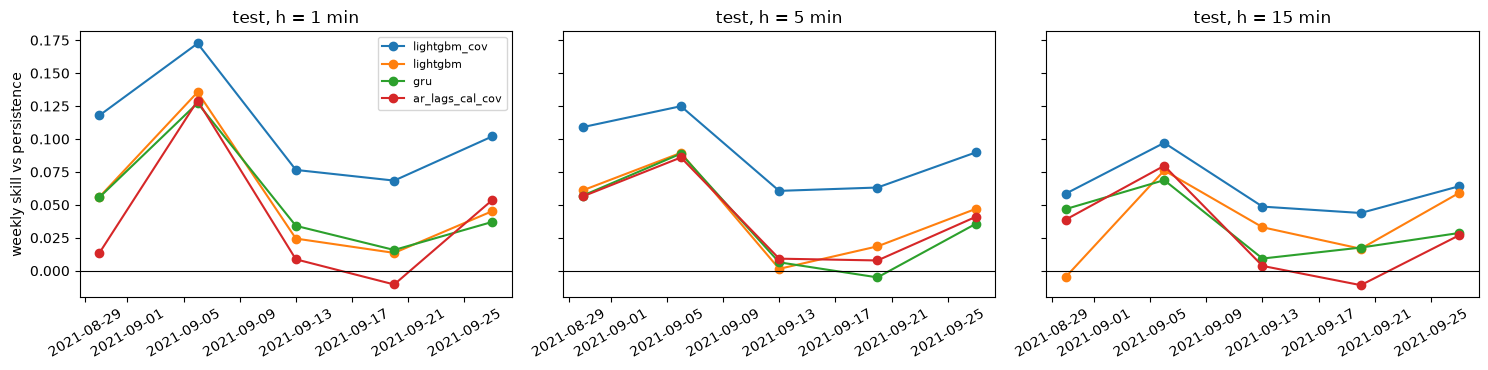

saved reports/figures/week4/02_weekly_skill_test.png


In [7]:
# Cell 7: figure: weekly skill vs persistence on test, best trained model per family, h = 1, 5, 15
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, h in zip(axs, HORIZONS):
    w = WK.filter((pl.col("h") == h) & (pl.col("targets") == "all"))
    for m in TOP[h][:4]:
        d = w.filter(pl.col("model") == m).sort("block_start")
        ax.plot(d["block_start"].to_list(), d["skill_MAE"].to_list(), marker="o", label=m)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"test, h = {h} min"); ax.tick_params(axis="x", rotation=30)
axs[0].set_ylabel("weekly skill vs persistence"); axs[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "02_weekly_skill_test.png", dpi=140); plt.show()
print("saved", (FIG / "02_weekly_skill_test.png").relative_to(ROOT))


In [8]:
# Cell 8: summary
S = {"freeze_record": FREEZE_F.name, "test_predictions_sha256": TEST_SHA, "best": {}, "dm_best_vs_second": {}}
for h in HORIZONS:
    b = BT.filter(pl.col("h") == h).sort("MAE_mean")
    S["best"][h] = b.select("model", "MAE_mean", "skill_MAE").head(5).to_dicts()
    r = DM.filter((pl.col("h") == h) & (pl.col("model_a") == TOP[h][0]) & (pl.col("model_b") == TOP[h][1]))
    S["dm_best_vs_second"][h] = r.to_dicts()[0] if r.height else None
    print(f"h={h:>2}: best {b['model'][0]} (skill {b['skill_MAE'][0]:+.3f}) | top 5: {b['model'].head(5).to_list()}")
(REP / "test_summary.json").write_text(json.dumps(S, indent=1, default=str))
print("written:", [p.name for p in REP.glob("*test*")])


h= 1: best lightgbm_cov (skill +0.114) | top 5: ['lightgbm_cov', 'lightgbm', 'timesfm_2p5_200m', 'gru', 'ar_lags_cal_cov']
h= 5: best lightgbm_cov (skill +0.090) | top 5: ['lightgbm_cov', 'lightgbm', 'gru', 'timesfm_2p5_200m', 'gru_uni']
h=15: best lightgbm_cov (skill +0.062) | top 5: ['lightgbm_cov', 'ar_lags_cal_cov', 'lightgbm', 'gru', 'gru_uni']
written: ['ramp_breakdown_test.csv', 'benchmark_test.csv', 'test_freeze_20261009_191127.json', 'test_predictions.parquet', 'dm_pairs_test.csv', 'test_runs.csv', 'test_summary.json', 'test_freeze.json', 'weekly_skill_test.csv']


In [9]:
# Cell 9: export outputs (save the notebook first with Cmd+S)
%run ../src/tools/nb_outputs_to_md.py 16_week4_test_evaluation.ipynb


written 16_week4_test_evaluation_outputs.md | code cells 10 | figures 0
